# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170333         # <-- your full roll number
NAME = "Sahil Sharma"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [3]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [4]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [5]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170333   Name: Sahil Sharma   Fingerprint: 8D00EDB8   Tickets: 15

Ticket_ID                                                                             Ticket_Text
      T01                                                           The LMS says 'Not Submitted'.
      T02     Python keeps disconnecting when I use mobile hotspot. It works on another computer.
      T03                                       The server stopped responding. Please resolve it.
      T04                               The laptop is not working. The same problem occurs again.
      T05   Printer crashes while opening after restarting the system. Is there another solution?
      T06                                 The password failed to open. I don't know what changed.
      T07                     I reinstalled the WiFi after the latest update. Can you check this?
      T08                                                   Nothing works and nobody has replied.
      T09                         

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [6]:

import string
import pandas as pd
import nltk
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Download required NLTK resources
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()


# Preprocessing function
def process_ticket(text):
    # Sentence tokenization
    sentences = sent_tokenize(text)

    # Word tokenization
    tokens = word_tokenize(text)

    # Extract punctuation tokens
    punct = [
        token for token in tokens
        if all(char in string.punctuation for char in token)
    ]

    # Extract stopwords
    stops = [
        token for token in tokens
        if token.lower() in stop_words
    ]

    # Remove punctuation and stopwords, lowercase and lemmatize
    final = [
        lemmatizer.lemmatize(token.lower())
        for token in tokens
        if token not in punct and token.lower() not in stop_words
    ]

    return {
        "sentences": sentences,
        "tokens": tokens,
        "punct": punct,
        "stops": stops,
        "final": final
    }


# Process every ticket
rows = []
all_results = []

for _, row in df.iterrows():
    result = process_ticket(row["Ticket_Text"])
    all_results.append(result)

    rows.append({
        "Ticket_ID": row["Ticket_ID"],
        "Sentences": " | ".join(result["sentences"]),
        "Tokens": " ".join(result["tokens"]),
        "Punctuation Tokens": " ".join(result["punct"]),
        "Stopwords": " ".join(result["stops"]),
        "Unique Tokens": " ".join(dict.fromkeys(result["tokens"])),
        "Final Tokens": " ".join(result["final"])
    })


# Create the output DataFrame
q1_df = pd.DataFrame(rows)


# Create TOTAL row
total_row = {
    "Ticket_ID": "TOTAL",
    "Sentences": " | ".join(
        s for r in all_results for s in r["sentences"]
    ),
    "Tokens": " ".join(
        t for r in all_results for t in r["tokens"]
    ),
    "Punctuation Tokens": " ".join(
        t for r in all_results for t in r["punct"]
    ),
    "Stopwords": " ".join(
        t for r in all_results for t in r["stops"]
    ),
    "Unique Tokens": " ".join(dict.fromkeys(
        t for r in all_results for t in r["tokens"]
    )),
    "Final Tokens": " ".join(
        t for r in all_results for t in r["final"]
    )
}

q1_df = pd.concat(
    [q1_df, pd.DataFrame([total_row])],
    ignore_index=True
)

# Display final table
display(q1_df)


,Ticket_ID,Sentences,Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
0,T01,The LMS says 'Not Submitted'.,The LMS says 'Not Submitted ' .,' .,The,The LMS says 'Not Submitted ' .,lm say 'not submitted
1,T02,Python keeps disconnecting when I use mobile h...,Python keeps disconnecting when I use mobile h...,. .,when I It on,Python keeps disconnecting when I use mobile h...,python keep disconnecting use mobile hotspot w...
2,T03,The server stopped responding. | Please resolv...,The server stopped responding . Please resolve...,. .,The it,The server stopped responding . Please resolve it,server stopped responding please resolve
3,T04,The laptop is not working. | The same problem ...,The laptop is not working . The same problem o...,. .,The is not The same again,The laptop is not working . same problem occur...,laptop working problem occurs
4,T05,Printer crashes while opening after restarting...,Printer crashes while opening after restarting...,. ?,while after the Is there,Printer crashes while opening after restarting...,printer crash opening restarting system anothe...
5,T06,The password failed to open. | I don't know wh...,The password failed to open . I do n't know wh...,. .,The to I do what,The password failed to open . I do n't know wh...,password failed open n't know changed
6,T07,I reinstalled the WiFi after the latest update...,I reinstalled the WiFi after the latest update...,. ?,I the after the Can you this,I reinstalled the WiFi after latest update . C...,reinstalled wifi latest update check
7,T08,Nothing works and nobody has replied.,Nothing works and nobody has replied .,.,and has,Nothing works and nobody has replied .,nothing work nobody replied
8,T09,Email me at helpdesk@university.edu.,Email me at helpdesk @ university.edu .,@ .,me at,Email me at helpdesk @ university.edu .,email helpdesk university.edu
9,T10,I cannot access the VPN when I use mobile hots...,I can not access the VPN when I use mobile hot...,. .,I can not the when I The same again,I can not access the VPN when use mobile hotsp...,access vpn use mobile hotspot problem occurs


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [7]:

import re
import pandas as pd

TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Regex patterns
patterns = {
    "Words > 5 letters": r"\b[A-Za-z]{6,}\b",
    "Numbers": r"(?<![\w.])\d+(?:,\d{3})*(?:\.\d+)*(?![\w.])",
    "Capitalized words": r"\b[A-Z][a-zA-Z]*\b",
    "Words starting with vowel": r"\b[AEIOUaeiou][a-zA-Z]*\b"
}

# Extract patterns from raw tickets
for name, pattern in patterns.items():
    print(f"\n--- {name} ---")
    for ticket_id, ticket in zip(df["Ticket_ID"], df["Ticket_Text"]):
        print(f"{ticket_id}: {re.findall(pattern, ticket)}")

# Replacement patterns
email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"

url_pattern = r"https?://[^\s<>]+|www\.[^\s<>]+"

phone_pattern = r"(?<!\w)(?:\+\d{1,3}[- ]?)?(?:\d{5}[- ]\d{5}|\d{4}[- ]\d{3}[- ]\d{4}|\d{3}[- ]\d{3}[- ]\d{4})(?!\w)"

def replace_patterns(text):
    text = re.sub(email_pattern, "<EMAIL>", text)
    text = re.sub(url_pattern, "<URL>", text)
    text = re.sub(phone_pattern, "<PHONE>", text)
    return text

# Test on the provided TEST_LINES
print("\n--- TEST_LINES after replacement ---")
for line in TEST_LINES:
    print(replace_patterns(line))

# Replace patterns in raw tickets
print("\n--- RAW TICKETS after replacement ---")
for ticket_id, ticket in zip(df["Ticket_ID"], df["Ticket_Text"]):
    print(f"{ticket_id}: {replace_patterns(ticket)}")



--- Words > 5 letters ---
T01: ['Submitted']
T02: ['Python', 'disconnecting', 'mobile', 'hotspot', 'another', 'computer']
T03: ['server', 'stopped', 'responding', 'Please', 'resolve']
T04: ['laptop', 'working', 'problem', 'occurs']
T05: ['Printer', 'crashes', 'opening', 'restarting', 'system', 'another', 'solution']
T06: ['password', 'failed', 'changed']
T07: ['reinstalled', 'latest', 'update']
T08: ['Nothing', 'nobody', 'replied']
T09: ['helpdesk', 'university']
T10: ['cannot', 'access', 'mobile', 'hotspot', 'problem', 'occurs']
T11: ['working', 'worked', 'yesterday']
T12: ['student', 'portal', 'restarting', 'system', 'changed']
T13: ['failed']
T14: ['uploaded']
T15: ['resetting', 'password', 'several']

--- Numbers ---
T01: []
T02: []
T03: []
T04: []
T05: []
T06: []
T07: []
T08: []
T09: []
T10: []
T11: []
T12: []
T13: []
T14: ['95.5']
T15: []

--- Capitalized words ---
T01: ['The', 'LMS', 'Not', 'Submitted']
T02: ['Python', 'I', 'It']
T03: ['The', 'Please']
T04: ['The', 'The']
T05: 

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [8]:

import re
import pandas as pd
from nltk.tokenize import RegexpTokenizer, word_tokenize

pattern = (
    r"https?://[^\s<>]+|www\.[^\s<>]+|"
    r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|"
    r"(?<!\w)(?:\+\d{1,3}[- ]?)?(?:\d{5}[- ]\d{5}|\d{4}[- ]\d{3}[- ]\d{4}|\d{3}[- ]\d{3}[- ]\d{4})(?!\w)|"
    r"\b\d+(?:,\d{3})*(?:\.\d+)+\b|"
    r"\b[A-Za-z]+(?:-[A-Za-z]+)+\b|"
    r"\b[A-Za-z]+(?:['’][A-Za-z]+)+\b|"
    r"\b[A-Za-z]+\b|"
    r"\d+(?:,\d{3})*(?:\.\d+)?|"
    r"[^\w\s]"
)

tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)

print("========== TEST_LINES ==========")

for i, line in enumerate(TEST_LINES, start=1):
    print(f"\nTest Line {i}:")
    print("Custom tokens:", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line))

print("\n========== RAW TICKETS ==========")

comparison_rows = []

for _, row in df.iterrows():
    text = row["Ticket_Text"]
    custom_tokens = my_tokenize(text)
    nltk_tokens = word_tokenize(text)

    comparison_rows.append({
        "Ticket_ID": row["Ticket_ID"],
        "Ticket_Text": text,
        "Custom Tokens": " ".join(custom_tokens),
        "word_tokenize Tokens": " ".join(nltk_tokens),
        "Custom Token Count": len(custom_tokens),
        "word_tokenize Count": len(nltk_tokens)
    })

q3_df = pd.DataFrame(comparison_rows)
display(q3_df)


========== TEST_LINES ==========

Test Line 1:
Custom tokens: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Test Line 2:
Custom tokens: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Test Line 3:
Custom tokens: ['The', 'state-of-the-art', 'lab', "isn't", 'open', ';', 'log-in', 'at', '5.30', 'p', '.', 'm', '.', "didn't", 'work', '.']
word_tokenize: ['The', 'state-of-the-art', 'lab', 'is', "n't", 'open', ';', 'log-in', 'at', '5.3

,Ticket_ID,Ticket_Text,Custom Tokens,word_tokenize Tokens,Custom Token Count,word_tokenize Count
0,T01,The LMS says 'Not Submitted'.,The LMS says ' Not Submitted ' .,The LMS says 'Not Submitted ' .,8,7
1,T02,Python keeps disconnecting when I use mobile h...,Python keeps disconnecting when I use mobile h...,Python keeps disconnecting when I use mobile h...,15,15
2,T03,The server stopped responding. Please resolve it.,The server stopped responding . Please resolve...,The server stopped responding . Please resolve...,9,9
3,T04,The laptop is not working. The same problem oc...,The laptop is not working . The same problem o...,The laptop is not working . The same problem o...,12,12
4,T05,Printer crashes while opening after restarting...,Printer crashes while opening after restarting...,Printer crashes while opening after restarting...,14,14
5,T06,The password failed to open. I don't know what...,The password failed to open . I don't know wha...,The password failed to open . I do n't know wh...,12,13
6,T07,I reinstalled the WiFi after the latest update...,I reinstalled the WiFi after the latest update...,I reinstalled the WiFi after the latest update...,14,14
7,T08,Nothing works and nobody has replied.,Nothing works and nobody has replied .,Nothing works and nobody has replied .,7,7
8,T09,Email me at helpdesk@university.edu.,Email me at helpdesk@university.edu .,Email me at helpdesk @ university.edu .,5,7
9,T10,I cannot access the VPN when I use mobile hots...,I cannot access the VPN when I use mobile hots...,I can not access the VPN when I use mobile hot...,17,18


**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [9]:

import pandas as pd
import nltk
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

nltk.download("averaged_perceptron_tagger", quiet=True)
nltk.download("averaged_perceptron_tagger_eng", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

porter = PorterStemmer()
lancaster = LancasterStemmer()
regex_stemmer = RegexpStemmer(r"(ing|edly|ed|ly|ies|s)$", min=3)
lemmatizer = WordNetLemmatizer()

unique_final_tokens = list(dict.fromkeys(
    token.lower()
    for result in all_results
    for token in result["final"]
    if token.isalpha()
))

def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    elif tag.startswith("V"):
        return wordnet.VERB
    elif tag.startswith("N"):
        return wordnet.NOUN
    elif tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN

pos_tags = nltk.pos_tag(unique_final_tokens)

rows = []

for word, tag in pos_tags:
    pos = get_wordnet_pos(tag)

    porter_result = porter.stem(word)
    lancaster_result = lancaster.stem(word)
    regex_result = regex_stemmer.stem(word)
    lemma_result = lemmatizer.lemmatize(word, pos=pos)

    if len({porter_result, lancaster_result, regex_result, lemma_result}) > 1:
        rows.append({
            "Word": word,
            "POS Tag": tag,
            "Porter Stem": porter_result,
            "Lancaster Stem": lancaster_result,
            "Regexp Stem": regex_result,
            "WordNet Lemma": lemma_result
        })

q4_df = pd.DataFrame(
    rows,
    columns=[
        "Word", "POS Tag", "Porter Stem",
        "Lancaster Stem", "Regexp Stem", "WordNet Lemma"
    ]
)

display(q4_df)
print("Total unique final tokens:", len(unique_final_tokens))
print("Words with differing outputs:", len(q4_df))


,Word,POS Tag,Porter Stem,Lancaster Stem,Regexp Stem,WordNet Lemma
0,submitted,VBN,submit,submit,submitt,submit
1,disconnecting,NN,disconnect,disconnect,disconnect,disconnecting
2,use,NN,use,us,use,use
3,mobile,JJ,mobil,mobl,mobile,mobile
4,another,DT,anoth,anoth,another,another
5,computer,NN,comput,comput,computer,computer
6,server,NN,server,serv,server,server
7,stopped,VBD,stop,stop,stopp,stop
8,please,NN,pleas,pleas,please,please
9,resolve,VB,resolv,resolv,resolve,resolve


Total unique final tokens: 55
Words with differing outputs: 31


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Corpus,Tokens,Unique Tokens,TTR
0,S1 (All tokens),180,89,0.4944
1,S2 (No punctuation),151,83,0.5497
2,S3 (Final tokens),84,59,0.7024
3,S4 (S3 after Porter),84,56,0.6667



Top 10 words in S1:
    Word  Frequency
0      .         22
1    the         16
2      i          9
3     is          4
4  after          4
5   open          4
6    n't          4
7    lms          3
8     it          3
9    not          3

Top 10 words in S3:
      Word  Frequency
0     open          4
1      n't          4
2       lm          3
3      use          2
4   mobile          2
5  hotspot          2
6     work          2
7  another          2
8  working          2
9  problem          2


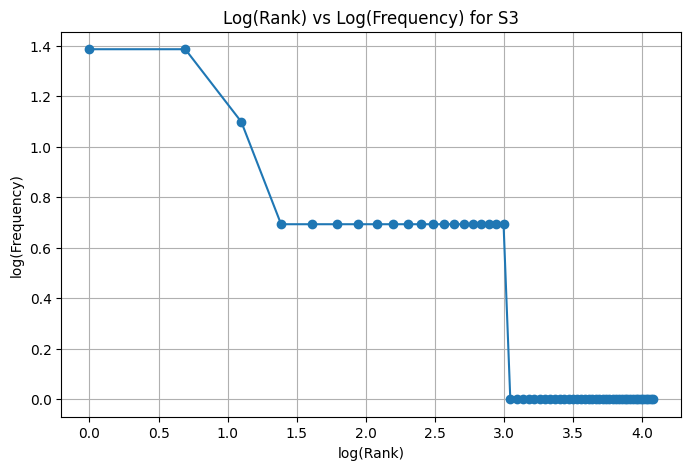


Top 5 bigrams in S1:
       Bigram  Frequency
0      (., i)          7
1    (., the)          6
2  (the, lms)          3
3   (when, i)          2
4    (i, use)          2

Top 5 bigrams in S3:
                 Bigram  Frequency
0         (use, mobile)          2
1     (mobile, hotspot)          2
2     (problem, occurs)          2
3  (restarting, system)          2
4        (failed, open)          2


In [10]:

import pandas as pd
import matplotlib.pyplot as plt
import nltk
from collections import Counter
from nltk.util import bigrams

S1 = [token.lower() for result in all_results for token in result["tokens"]]

S2 = [
    token.lower()
    for result in all_results
    for token in result["tokens"]
    if token not in result["punct"]
]

S3 = [token.lower() for result in all_results for token in result["final"]]

S4 = [porter.stem(token) for token in S3]

corpora = {
    "S1 (All tokens)": S1,
    "S2 (No punctuation)": S2,
    "S3 (Final tokens)": S3,
    "S4 (S3 after Porter)": S4
}

stats = []

for name, tokens in corpora.items():
    stats.append({
        "Corpus": name,
        "Tokens": len(tokens),
        "Unique Tokens": len(set(tokens)),
        "TTR": round(len(set(tokens)) / len(tokens), 4) if tokens else 0
    })

stats_df = pd.DataFrame(stats)
display(stats_df)

print("\nTop 10 words in S1:")
print(pd.DataFrame(Counter(S1).most_common(10), columns=["Word", "Frequency"]))

print("\nTop 10 words in S3:")
print(pd.DataFrame(Counter(S3).most_common(10), columns=["Word", "Frequency"]))

freq_s3 = Counter(S3).most_common()
ranks = list(range(1, len(freq_s3) + 1))
frequencies = [frequency for word, frequency in freq_s3]

plt.figure(figsize=(8, 5))
plt.plot(
    [__import__("math").log(rank) for rank in ranks],
    [__import__("math").log(freq) for freq in frequencies],
    marker="o",
    linestyle="-"
)
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.title("Log(Rank) vs Log(Frequency) for S3")
plt.grid(True)
plt.show()

print("\nTop 5 bigrams in S1:")
print(pd.DataFrame(
    Counter(bigrams(S1)).most_common(5),
    columns=["Bigram", "Frequency"]
))

print("\nTop 5 bigrams in S3:")
print(pd.DataFrame(
    Counter(bigrams(S3)).most_common(5),
    columns=["Bigram", "Frequency"]
))


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR changes from S1 to S4 because preprocessing removes punctuation and stopwords, while stemming converts similar words into a common root form. This reduces the total number of tokens and may also reduce the number of unique words. As a result, the Type Token Ratio changes depending on how much the vocabulary is reduced compared to the total tokens.